# Fase 2 CRISP-DM — Comprensión de los Datos (EDA)

Este cuaderno explora el inventario combinado del proyecto:
- **Fotos propias validadas por el equipo** (`data/own_photos/`, 6 especies).
- **Recortes individuales segmentados de `Mixed Qualit_Fruits`** (`data/mixed_crops/`).
- **Muestra estratificada de Kaggle *Fruit Quality Classification*** (`data/external/`).

Se analiza el balanceo de clases, la cobertura por especie y origen, la variabilidad de resoluciones/relaciones de aspecto y ejemplos visuales reales por categoría.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import FRUITNET_SPLITS_CSV, OWN_ANNOTATIONS_CSV, QUALITY_CLASSES

df = pd.read_csv(FRUITNET_SPLITS_CSV)
own_df = pd.read_csv(OWN_ANNOTATIONS_CSV)
print(f"Total dataset combinado: {len(df)} imágenes | Fotos propias: {len(own_df)}")
display(df.head())

Total dataset combinado: 971 imágenes | Fotos propias: 307


,image_path,species,quality,width,height,sha256,source,group_id,leakage_group,split
0,data/own_photos/banano/Buena/banano_001_buena.jpg,banano,Buena,466,1024,761bf6dc4675361c562afa7a23f4ee5986410138ad7451...,Propia,own_banano_761bf6dc4675,grp_0000,val
1,data/own_photos/banano/Buena/banano_002_buena.jpg,banano,Buena,541,1024,6d8b6891dd4edfc8fb937821bd743fd206399be2b39956...,Propia,own_banano_6d8b6891dd4e,grp_0001,train
2,data/own_photos/banano/Buena/banano_003_buena.jpg,banano,Buena,527,1024,f4459f990532491c853229390e4ed0229d1a2bd21f2223...,Propia,own_banano_f4459f990532,grp_0002,train
3,data/own_photos/banano/Buena/banano_004_buena.jpg,banano,Buena,502,1024,1c881b1ff7047b6f204dec8ea035c63555fd0706093cac...,Propia,own_banano_1c881b1ff704,grp_0003,train
4,data/own_photos/banano/Buena/banano_005_buena.jpg,banano,Buena,461,1024,62fcf8078cbbded733d0dc8aed15e5cf9ceb7e2cbe61ed...,Propia,own_banano_62fcf8078cbb,grp_0004,test


In [2]:
print("=== Conteo por origen y calidad ===")
display(pd.crosstab(df["source"], df["quality"], margins=True))

print("\n=== Conteo por especie y calidad ===")
display(pd.crosstab(df["species"], df["quality"], margins=True))

print("\n=== Distribución porcentual de clases ===")
pct = (df["quality"].value_counts(normalize=True).reindex(QUALITY_CLASSES) * 100).round(2)
display(pct.to_frame("Porcentaje (%)"))

=== Conteo por origen y calidad ===


quality,Buena,Mala,Regular,All
source,,,,
FruitNet_Kaggle,180,400,0,580
FruitNet_Mixed_Segmentada,0,0,84,84
Propia,255,37,15,307
All,435,437,99,971



=== Conteo por especie y calidad ===


quality,Buena,Mala,Regular,All
species,,,,
banano,67,110,26,203
limon,82,100,27,209
mango,38,13,7,58
manzana,74,100,15,189
naranja,116,114,24,254
tomate_arbol,58,0,0,58
All,435,437,99,971



=== Distribución porcentual de clases ===


,Porcentaje (%)
quality,
Buena,44.80
Regular,10.20
Mala,45.01


width               height               \
                            min  median   max    min median   max   
source                                                              
FruitNet_Kaggle             144   256.0   256    144  256.0   256   
FruitNet_Mixed_Segmentada    33    52.0   175     28   55.0   192   
Propia                      450  1024.0  1024    468  468.0  1024   

                          aspect_ratio               
                                   min median   max  
source                                               
FruitNet_Kaggle                   0.56   1.00  1.78  
FruitNet_Mixed_Segmentada         0.28   0.98  3.64  
Propia                            0.44   2.19  2.19

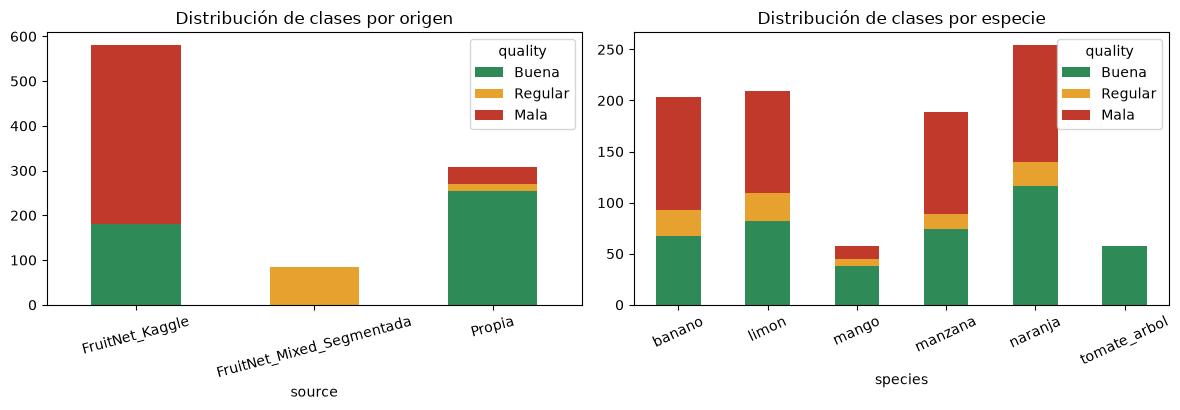

In [3]:
# Análisis de resoluciones y relación de aspecto (evidencia la variabilidad entre cámaras y orígenes)
df["aspect_ratio"] = (df["width"] / df["height"]).round(2)
display(df.groupby("source")[["width", "height", "aspect_ratio"]].agg(["min", "median", "max"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ct_src = pd.crosstab(df["source"], df["quality"]).reindex(columns=list(QUALITY_CLASSES), fill_value=0)
ct_src.plot(kind="bar", stacked=True, ax=axes[0], color=["#2E8B57", "#E6A12E", "#C0392B"])
axes[0].set_title("Distribución de clases por origen")
axes[0].tick_params(axis="x", rotation=15)

ct_sp = pd.crosstab(df["species"], df["quality"]).reindex(columns=list(QUALITY_CLASSES), fill_value=0)
ct_sp.plot(kind="bar", stacked=True, ax=axes[1], color=["#2E8B57", "#E6A12E", "#C0392B"])
axes[1].set_title("Distribución de clases por especie")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

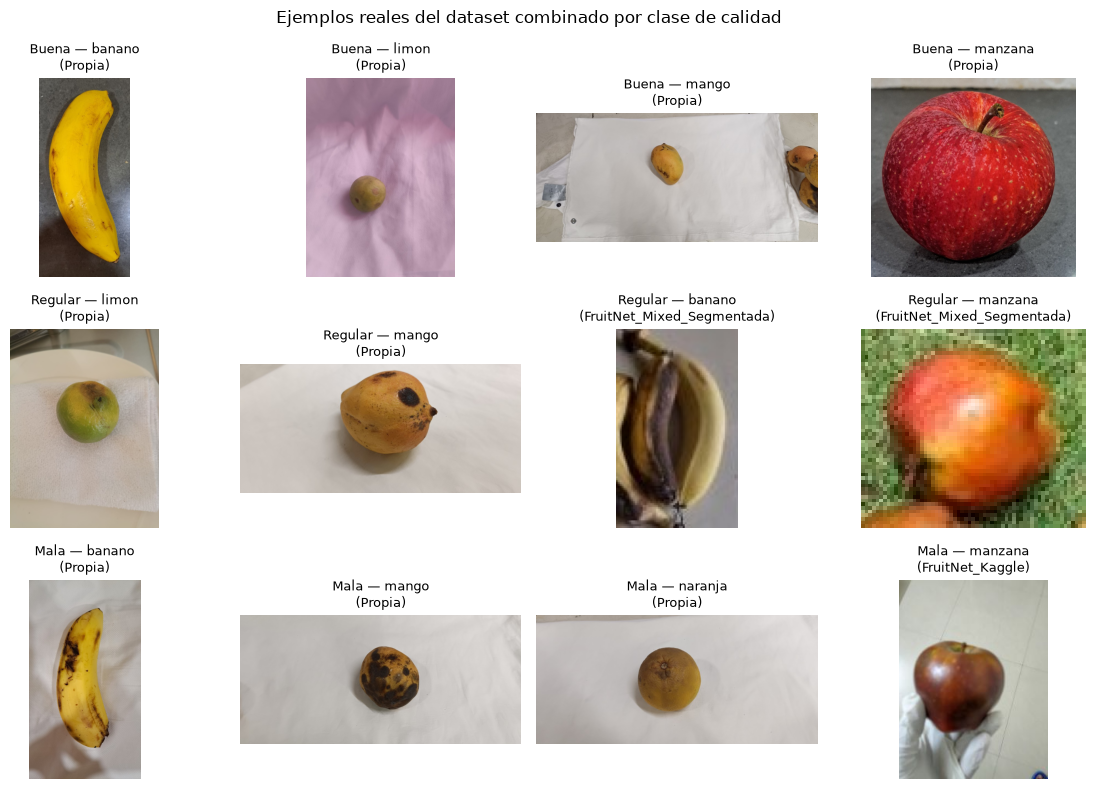

In [4]:
# Galería de muestras reales por clase (Buena, Regular, Mala)
fig, axes = plt.subplots(3, 4, figsize=(12, 8))
for r_idx, cls in enumerate(QUALITY_CLASSES):
    sub = df[df["quality"].eq(cls)]
    picks = sub.groupby("species", group_keys=False).head(1).head(4)
    if len(picks) < 4:
        picks = sub.head(4)
    for c_idx in range(4):
        ax = axes[r_idx, c_idx]
        ax.axis("off")
        if c_idx < len(picks):
            row = picks.iloc[c_idx]
            img = Image.open(PROJECT_ROOT / row["image_path"]).convert("RGB")
            ax.imshow(img)
            ax.set_title(f"{cls} — {row['species']}\n({row['source']})", fontsize=9)
plt.suptitle("Ejemplos reales del dataset combinado por clase de calidad", fontsize=12)
plt.tight_layout()
plt.show()

### Hallazgos clave del EDA
1. **Desbalanceo controlado:** `Buena` (~44.8 %) y `Mala` (~45.0 %) están balanceadas, mientras `Regular` representa ~10.2 % (`99` imágenes: 15 propias + 84 recortes validados de `Mixed Qualit_Fruits`). Esto exige usar **pesos por clase** y **Macro-F1** como métrica principal.
2. **Heterogeneidad de captura:** las fotos propias varían entre formato horizontal panorámico (`1024×468`, tela blanca), vertical (`768×1024`, limones) y primer plano sobre mesón gris oscuro (`banano`, `manzana`), mientras Kaggle emplea recortes `256×256` o `256×192`.
3. **Cobertura por especie:** `tomate_arbol` solo cuenta con ejemplares `Buena` en las fotos propias; esto se tendrá en cuenta al desglosar métricas por especie en Fase 5.